# Temperatura de bulbo úmido: máximas diárias e percentil 95

A maior temperatura de bulbo úmido observada em cada dia é calculada a partir da série horária. O percentil 95 é então aplicado à série de máximas diárias de 1995 a 2025.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Série processada de 1995--2024 e arquivo bruto de 2025
arquivo_historico = Path("series_temporais_csv/temperatura_bulbo_umido_1995_2024.csv")
arquivo_2025 = Path(
    "dado_bruto/56_Ana Carolina de Oliveira Rodrigues/"
    "tempbulboumido/2025.xls"
)
bulbo_umido_historico = pd.read_csv(arquivo_historico, parse_dates=["data_hora"])

MESES_2025 = {
    "JAN": 1, "FEV": 2, "MAR": 3, "ABR": 4, "MAI": 5, "JUN": 6,
    "JUL": 7, "AGO": 8, "SET": 9, "OUT": 10, "NOV": 11, "DEZ": 12,
}

def ler_mes_2025(aba, mes):
    """Converte uma aba mensal (hora x dia) do arquivo bruto em série horária."""
    bruto = pd.read_excel(arquivo_2025, sheet_name=aba, header=None)
    linha_dias = bruto.index[
        bruto.iloc[:, 0].astype(str).str.strip().str.upper().eq("H/D")
    ][0]

    dias = pd.to_numeric(bruto.iloc[linha_dias, 1:], errors="coerce")
    horas = pd.to_numeric(bruto.iloc[linha_dias + 1 :, 0], errors="coerce")
    valores = bruto.iloc[linha_dias + 1 :, 1:].copy()
    valores.index = horas
    valores.columns = dias
    valores = valores.loc[valores.index.notna(), valores.columns.notna()]

    tabela = (
        valores.rename_axis(index="hora", columns="dia")
        .reset_index()
        .melt(id_vars="hora", var_name="dia", value_name="valor")
    )
    tabela["hora"] = pd.to_numeric(tabela["hora"], errors="coerce")
    tabela["dia"] = pd.to_numeric(tabela["dia"], errors="coerce")
    tabela["valor"] = pd.to_numeric(tabela["valor"], errors="coerce")
    tabela = tabela.dropna(subset=["hora", "dia"])
    tabela = tabela[tabela["hora"].between(1, 24)]

    ultimo_dia = pd.Period(year=2025, month=mes, freq="M").days_in_month
    tabela = tabela[tabela["dia"].between(1, ultimo_dia)]
    tabela["data_hora"] = (
        pd.to_datetime({"year": 2025, "month": mes, "day": tabela["dia"].astype(int)})
        + pd.to_timedelta(tabela["hora"] - 1, unit="h")
    )
    return tabela[["data_hora", "valor"]]

bulbo_umido_2025 = pd.concat(
    [ler_mes_2025(aba, mes) for aba, mes in MESES_2025.items()],
    ignore_index=True,
).sort_values("data_hora")

bulbo_umido = pd.concat([bulbo_umido_historico, bulbo_umido_2025], ignore_index=True)
bulbo_umido = bulbo_umido.drop_duplicates(subset="data_hora", keep="first")
bulbo_umido["valor"] = bulbo_umido["valor"].mask(bulbo_umido["valor"].eq(-99))

# Máxima de bulbo úmido de cada dia e percentil 95 dessas máximas
temperaturas_bulbo_umido_maximas_diarias = (
    bulbo_umido.set_index("data_hora")["valor"]
    .resample("D")
    .max()
    .rename("temperatura_bulbo_umido_maxima_diaria")
)
percentil_95_bulbo_umido = temperaturas_bulbo_umido_maximas_diarias.quantile(0.95)

print(
    f"Período analisado: {temperaturas_bulbo_umido_maximas_diarias.index.min():%d/%m/%Y} "
    f"a {temperaturas_bulbo_umido_maximas_diarias.index.max():%d/%m/%Y}"
)
print(f"Dias com máxima calculada: {temperaturas_bulbo_umido_maximas_diarias.notna().sum():,}")
print(f"Percentil 95 das máximas diárias de bulbo úmido: {percentil_95_bulbo_umido:.1f} °C")

temperaturas_bulbo_umido_maximas_diarias.to_frame().head()

Período analisado: 01/01/1995 a 31/12/2025
Dias com máxima calculada: 11,323
Percentil 95 das máximas diárias de bulbo úmido: 23.2 °C


,temperatura_bulbo_umido_maxima_diaria
data_hora,
1995-01-01,21.5
1995-01-02,22.3
1995-01-03,22.6
1995-01-04,21.8
1995-01-05,22.9


## Frequência de intervalos quentes de bulbo úmido

Um intervalo é uma sequência de **três ou mais dias consecutivos** em que a máxima diária de bulbo úmido é **maior que o percentil 95**. Cada intervalo é contado uma vez, no mês em que se inicia.

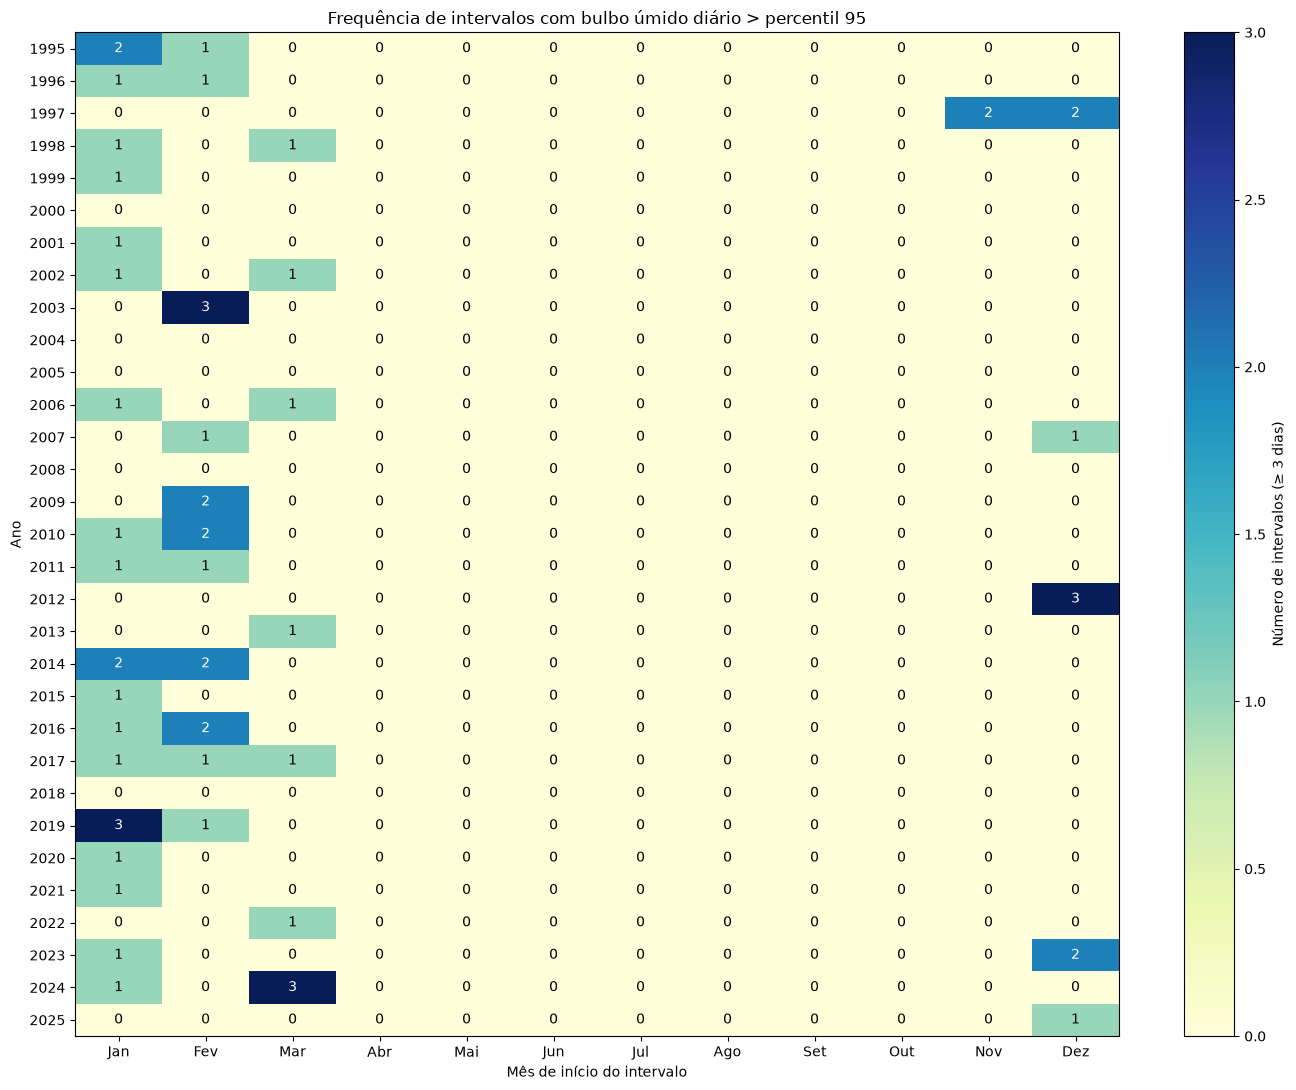

Intervalos de pelo menos 3 dias encontrados: 59


,grupo,inicio,fim,duracao_dias,maxima_no_evento,ano,mes
1,4,1995-01-13,1995-01-16,4,23.9,1995,1
3,8,1995-01-25,1995-01-27,3,24.2,1995,1
5,12,1995-02-25,1995-02-27,3,24.4,1995,2
11,24,1996-01-27,1996-01-29,3,24.6,1996,1
15,32,1996-02-25,1996-02-27,3,23.9,1996,2
27,56,1997-11-01,1997-11-03,3,24.6,1997,11
28,58,1997-11-10,1997-11-13,4,25.1,1997,11
30,62,1997-12-23,1997-12-28,6,25.0,1997,12
31,64,1997-12-30,1998-01-07,9,24.4,1997,12
32,66,1998-01-26,1998-02-10,16,24.8,1998,1


In [2]:
# Identifica sequências consecutivas acima do percentil 95
serie_diaria_bulbo_umido = (
    temperaturas_bulbo_umido_maximas_diarias
    .rename_axis("data")
    .reset_index()
)
serie_diaria_bulbo_umido["acima_p95"] = (
    serie_diaria_bulbo_umido["temperatura_bulbo_umido_maxima_diaria"]
    > percentil_95_bulbo_umido
)
serie_diaria_bulbo_umido["grupo"] = (
    serie_diaria_bulbo_umido["acima_p95"]
    .ne(serie_diaria_bulbo_umido["acima_p95"].shift())
    .cumsum()
)

eventos_bulbo_umido = (
    serie_diaria_bulbo_umido.loc[serie_diaria_bulbo_umido["acima_p95"]]
    .groupby("grupo", as_index=False)
    .agg(
        inicio=("data", "min"),
        fim=("data", "max"),
        duracao_dias=("data", "size"),
        maxima_no_evento=("temperatura_bulbo_umido_maxima_diaria", "max"),
    )
    .query("duracao_dias >= 3")
)

# A frequência é atribuída ao ano e ao mês de início de cada intervalo.
eventos_bulbo_umido["ano"] = eventos_bulbo_umido["inicio"].dt.year
eventos_bulbo_umido["mes"] = eventos_bulbo_umido["inicio"].dt.month

meses = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun",
         "Jul", "Ago", "Set", "Out", "Nov", "Dez"]
frequencia_eventos_bulbo_umido = (
    eventos_bulbo_umido.pivot_table(
        index="ano", columns="mes", values="grupo", aggfunc="count", fill_value=0
    )
    .reindex(
        index=range(
            bulbo_umido["data_hora"].dt.year.min(),
            bulbo_umido["data_hora"].dt.year.max() + 1,
        ),
        columns=range(1, 13),
        fill_value=0,
    )
)
frequencia_eventos_bulbo_umido.columns = meses

fig, ax = plt.subplots(figsize=(14, 11))
imagem = ax.imshow(frequencia_eventos_bulbo_umido, cmap="YlGnBu", aspect="auto")

ax.set_xticks(range(12), meses)
ax.set_yticks(
    range(len(frequencia_eventos_bulbo_umido.index)),
    frequencia_eventos_bulbo_umido.index,
)
ax.set_title("Frequência de intervalos com bulbo úmido diário > percentil 95")
ax.set_xlabel("Mês de início do intervalo")
ax.set_ylabel("Ano")

# Mostra a contagem em cada célula do heatmap.
valor_maximo = frequencia_eventos_bulbo_umido.to_numpy().max()
for linha, ano in enumerate(frequencia_eventos_bulbo_umido.index):
    for coluna, mes in enumerate(frequencia_eventos_bulbo_umido.columns):
        quantidade = frequencia_eventos_bulbo_umido.loc[ano, mes]
        cor_texto = "white" if quantidade > valor_maximo / 2 else "black"
        ax.text(coluna, linha, int(quantidade), ha="center", va="center", color=cor_texto)

fig.colorbar(imagem, ax=ax, label="Número de intervalos (≥ 3 dias)")
fig.tight_layout()
plt.show()

print(f"Intervalos de pelo menos 3 dias encontrados: {len(eventos_bulbo_umido)}")
eventos_bulbo_umido